# 🌧️ Will It Rain Tomorrow in Sri Lanka?
## Ensemble Learning Dashboard: Bagging vs Boosting vs Stacking (+ Hybrid RF + ANN)

**Student:** Lisorthman.V &nbsp;|&nbsp; **Index No:** 225063F

---

### Problem statement
Rain shapes daily life in Sri Lanka: paddy cultivation, tea estates, fishing, construction, flood preparedness and even the daily commute. Rainfall here is driven by two monsoons and two inter-monsoon periods, and it varies sharply between the **Wet, Intermediate and Dry zones**.

**Goal:** given today's weather at a Sri Lankan city, predict whether **tomorrow will be a rainy day** (≥ 1 mm of precipitation, a common meteorological threshold for a "rain day").

This is a **binary classification** problem. We compare three ensemble families on it:

| Family | Idea | Models in this notebook |
|---|---|---|
| **Bagging** | Many trees trained in parallel on bootstrap samples, then averaged → lower variance | Random Forest, Extra Trees, Bagged Decision Trees |
| **Boosting** | Trees trained sequentially, each fixing the previous errors → lower bias | AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost |
| **Stacking** | Heterogeneous base models, with a meta-model learning how to combine them | RF + LightGBM + KNN + Logistic Regression → Logistic Regression meta-learner |
| **Hybrid** | Tree model + neural network | Random Forest + ANN (MLP), soft-voting |

### Dataset (Sri Lankan, real data)
* **Source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (ERA5 reanalysis by ECMWF / Copernicus), free and open (CC BY 4.0).
* **Coverage:** **15 Sri Lankan cities** across all 9 provinces and all 3 climate zones, daily, **1 Jan 2015 to 31 Dec 2025** → **60,270 rows**.
* Downloaded with `fetch_data.py` (included in the repository).

In [1]:
import warnings, json, time, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
os.makedirs("models", exist_ok=True)

## 1. Load the data

In [2]:
raw = pd.read_csv("data/sri_lanka_weather.csv", parse_dates=["date"])
print(raw.shape)
raw.head()

(60270, 23)


,date,city,district,province,climate_zone,latitude,longitude,temperature_2m_max,temperature_2m_min,temperature_2m_mean,...,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,relative_humidity_2m_mean,pressure_msl_mean,cloud_cover_mean,dew_point_2m_mean
0,2015-01-01,Colombo,Colombo,Western,Wet,6.9271,79.8612,28.4,23.2,25.8,...,7.0,11.4,27.4,210,18.30,3.51,88,1009.8,39,23.6
1,2015-01-02,Colombo,Colombo,Western,Wet,6.9271,79.8612,28.8,22.9,25.5,...,0.0,9.6,22.0,282,19.63,3.95,82,1011.8,28,22.1
2,2015-01-03,Colombo,Colombo,Western,Wet,6.9271,79.8612,29.9,20.9,25.6,...,0.0,9.9,20.2,300,22.94,4.59,81,1012.3,58,21.9
3,2015-01-04,Colombo,Colombo,Western,Wet,6.9271,79.8612,29.8,23.2,26.1,...,0.0,8.8,20.9,331,18.36,3.78,82,1011.8,37,22.6
4,2015-01-05,Colombo,Colombo,Western,Wet,6.9271,79.8612,29.6,23.0,26.4,...,2.0,7.9,19.4,6,19.99,4.06,83,1011.0,32,23.1


In [3]:
raw.groupby(["climate_zone", "city"]).agg(
    days=("date", "count"),
    avg_daily_rain_mm=("precipitation_sum", "mean"),
    annual_rain_mm=("precipitation_sum", lambda s: s.sum() / 11),
    avg_max_temp=("temperature_2m_max", "mean"),
).round(1).sort_values("annual_rain_mm", ascending=False)

days  avg_daily_rain_mm  annual_rain_mm  \
climate_zone city                                                    
Wet          Ratnapura     4018               10.8          3942.0   
             Galle         4018                8.2          2983.1   
             Gampaha       4018                8.1          2948.0   
             Colombo       4018                7.8          2834.9   
Intermediate Badulla       4018                6.3          2311.0   
             Kurunegala    4018                6.0          2190.1   
Wet          Nuwara Eliya  4018                5.5          2006.0   
             Kandy         4018                4.9          1800.4   
Dry          Batticaloa    4018                4.7          1733.6   
             Puttalam      4018                4.7          1722.9   
             Polonnaruwa   4018                4.4          1611.0   
             Trincomalee   4018                4.3          1567.9   
             Anuradhapura  4018                4.2          1549.9   
             Jaffna        4018                3.7          1342.5   
             Hambantota    4018                3.4          1257.7   

                           avg_max_temp  
climate_zone city                        
Wet          Ratnapura             29.8  
             Galle                 29.0  
             Gampaha               30.4  
             Colombo               29.6  
Intermediate Badulla               28.1  
             Kurunegala            30.3  
Wet          Nuwara Eliya          19.9  
             Kandy                 28.1  
Dry          Batticaloa            31.4  
             Puttalam              30.2  
             Polonnaruwa           32.3  
             Trincomalee           31.5  
             Anuradhapura          31.3  
             Jaffna                30.0  
             Hambantota            30.8

## 2. Exploratory data analysis

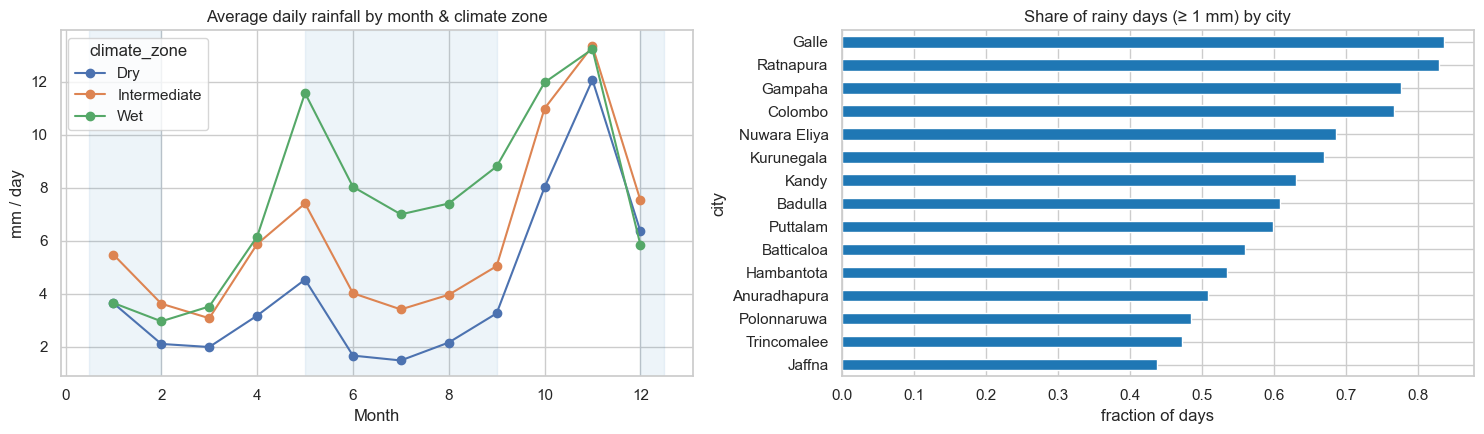

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
monthly = (raw.assign(month=raw.date.dt.month)
              .groupby(["climate_zone", "month"])["precipitation_sum"].mean().unstack(0))
monthly.plot(ax=axes[0], marker="o")
axes[0].set(title="Average daily rainfall by month & climate zone", xlabel="Month", ylabel="mm / day")
for x0, x1, lab in [(5, 9, "SW monsoon"), (12, 12.5, ""), (0.5, 2, "NE monsoon")]:
    axes[0].axvspan(x0, x1, alpha=0.08, color="tab:blue")
rain_day = (raw.assign(rain=raw.precipitation_sum >= 1).groupby("city")["rain"].mean()
               .sort_values())
rain_day.plot.barh(ax=axes[1], color="tab:blue")
axes[1].set(title="Share of rainy days (≥ 1 mm) by city", xlabel="fraction of days")
plt.tight_layout(); plt.show()

**Observations**
* The **Wet zone** (Colombo, Ratnapura, Galle) peaks during the **South-West monsoon (May–Sep)** and the second inter-monsoon (Oct–Nov).
* The **Dry zone** (Trincomalee, Batticaloa, Jaffna, Anuradhapura) gets most of its rain from the **North-East monsoon (Dec–Feb)** and is very dry mid-year.
* So **location × season** interactions matter a lot. Tree ensembles capture these interactions naturally, while a linear model cannot.

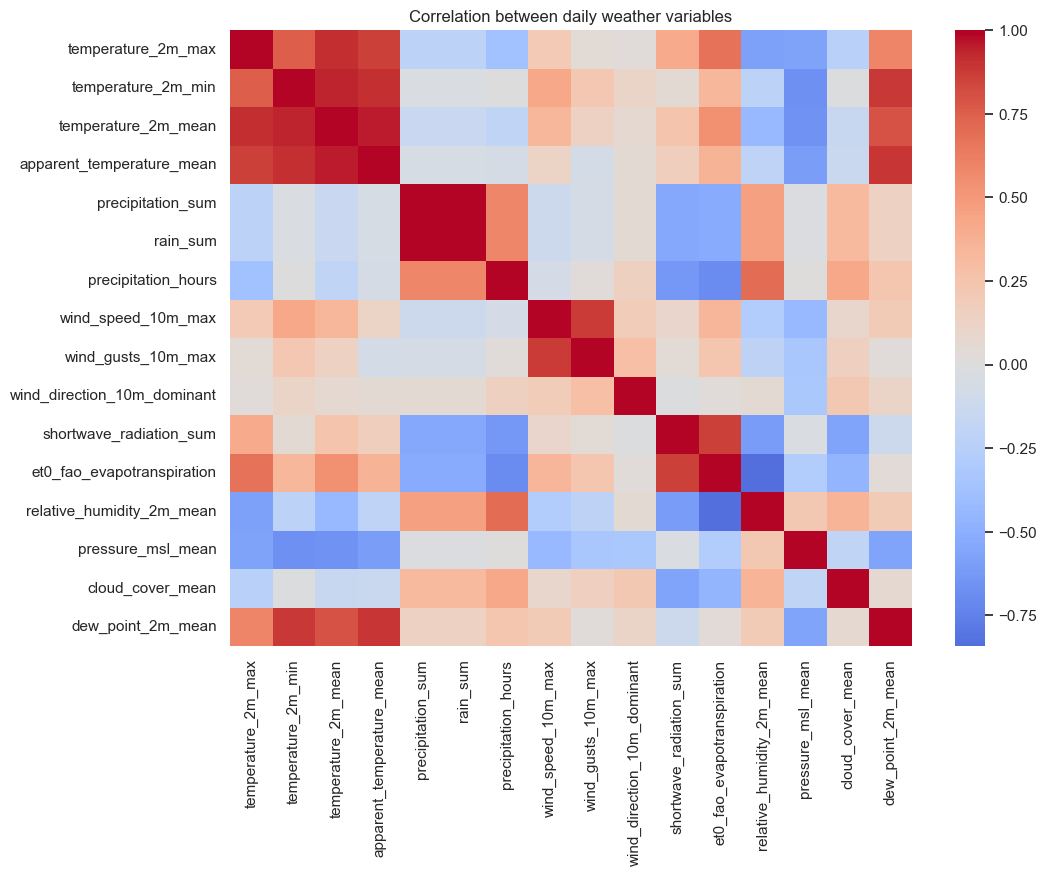

In [5]:
corr = raw.drop(columns=["latitude", "longitude"]).select_dtypes("number").corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between daily weather variables"); plt.show()

## 3. Preprocessing & feature engineering

1. **Missing values:** check and fill (ERA5 is almost complete, but we still handle it).
2. **Target:** `rain_tomorrow = 1` if the next day's precipitation at the same city is ≥ 1 mm.
3. **Lag / rolling features** (per city, using only past data): yesterday's rain, 3- and 7-day rain totals, 24h pressure / humidity change.
4. **Seasonality:** cyclical month and day-of-year encodings, plus a Sri Lankan **monsoon season** category.
5. **Wind direction** → sine / cosine (359° and 1° are neighbours).
6. **Categorical encoding:** `city`, `climate_zone`, `province`, `monsoon_season` → one-hot (inside a pipeline).

In [6]:
df = raw.sort_values(["city", "date"]).reset_index(drop=True)
print("Missing values per column before cleaning:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "  none")

num_raw = df.select_dtypes("number").columns
df[num_raw] = df.groupby("city")[num_raw].transform(lambda s: s.interpolate(limit_direction="both"))
df = df.drop(columns=["rain_sum"])   # ~identical to precipitation_sum in Sri Lanka (no snow) → redundant

Missing values per column before cleaning:
  none


In [7]:
def monsoon_season(m):
    if m in (12, 1, 2):  return "NE Monsoon"
    if m in (3, 4):      return "First Inter-monsoon"
    if m in (5, 6, 7, 8, 9): return "SW Monsoon"
    return "Second Inter-monsoon"          # Oct, Nov

g = df.groupby("city")
df["rain_lag1"]       = g["precipitation_sum"].shift(1)
df["rain_lag2"]       = g["precipitation_sum"].shift(2)
df["rain_3d_sum"]     = g["precipitation_sum"].transform(lambda s: s.rolling(3).sum())
df["rain_7d_sum"]     = g["precipitation_sum"].transform(lambda s: s.rolling(7).sum())
df["pressure_change"] = g["pressure_msl_mean"].diff()
df["humidity_change"] = g["relative_humidity_2m_mean"].diff()
df["temp_range"]      = df["temperature_2m_max"] - df["temperature_2m_min"]

df["month"]     = df.date.dt.month
df["month_sin"] = np.sin(2 * np.pi * df.month / 12)
df["month_cos"] = np.cos(2 * np.pi * df.month / 12)
doy = df.date.dt.dayofyear
df["doy_sin"]   = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"]   = np.cos(2 * np.pi * doy / 365.25)
df["wind_dir_sin"] = np.sin(np.deg2rad(df.wind_direction_10m_dominant))
df["wind_dir_cos"] = np.cos(np.deg2rad(df.wind_direction_10m_dominant))
df["monsoon_season"] = df.month.map(monsoon_season)

# ---- target: will tomorrow be a rain day? ----
df["rain_tomorrow"] = (g["precipitation_sum"].shift(-1) >= 1.0).astype("float")
df.loc[g["precipitation_sum"].shift(-1).isna(), "rain_tomorrow"] = np.nan

df = df.dropna(subset=["rain_tomorrow", "rain_7d_sum", "pressure_change"]).reset_index(drop=True)
df["rain_tomorrow"] = df["rain_tomorrow"].astype(int)
print(df.shape)

(60165, 38)


In [8]:
CAT_FEATURES = ["city", "climate_zone", "province", "monsoon_season"]
NUM_FEATURES = [
    "latitude", "longitude",
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean",
    "temp_range", "precipitation_sum", "precipitation_hours", "wind_speed_10m_max",
    "wind_gusts_10m_max", "wind_dir_sin", "wind_dir_cos", "shortwave_radiation_sum",
    "et0_fao_evapotranspiration", "relative_humidity_2m_mean", "pressure_msl_mean",
    "cloud_cover_mean", "dew_point_2m_mean",
    "rain_lag1", "rain_lag2", "rain_3d_sum", "rain_7d_sum", "pressure_change", "humidity_change",
    "month_sin", "month_cos", "doy_sin", "doy_cos",
]
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "rain_tomorrow"
print(len(FEATURES), "input features")

33 input features


### Class balance

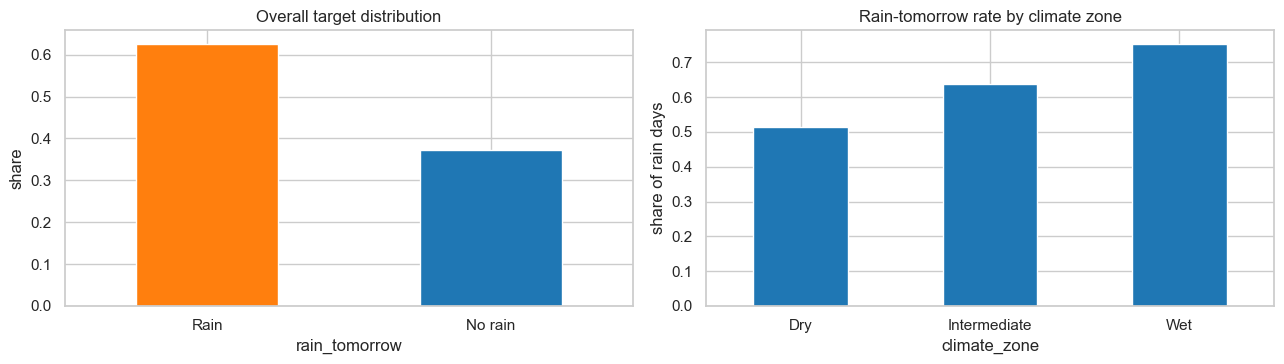

rain_tomorrow
1    0.627
0    0.373
Name: proportion, dtype: float64


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df[TARGET].value_counts(normalize=True).rename({0: "No rain", 1: "Rain"}).plot.bar(ax=ax[0], color=["tab:orange", "tab:blue"])
ax[0].set(title="Overall target distribution", ylabel="share"); ax[0].tick_params(axis="x", rotation=0)
df.groupby("climate_zone")[TARGET].mean().plot.bar(ax=ax[1], color="tab:blue")
ax[1].set(title="Rain-tomorrow rate by climate zone", ylabel="share of rain days"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

Overall the classes are close to balanced, but **within the Dry zone rain days are the minority**. To make sure the models don't simply learn "dry zone ⇒ no rain", we use **class weights** (`class_weight="balanced"` / `scale_pos_weight` / `auto_class_weights`) wherever the algorithm supports them. With a near-balanced overall split this is gentler than SMOTE, and it doesn't create synthetic weather days that never happened.

### Train / test split: chronological (no look-ahead leakage)
Weather is a time series, so a random split would leak information (e.g. the 3-day rain sum of a training day overlaps a test day). We therefore train on **2015–2023** and test on the unseen years **2024–2025**, exactly as a real forecasting model would be used.

In [10]:
train = df[df.date < "2024-01-01"]
test  = df[df.date >= "2024-01-01"]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(f"Train: {X_train.shape}  {train.date.min().date()} → {train.date.max().date()}  rain rate={y_train.mean():.3f}")
print(f"Test : {X_test.shape}  {test.date.min().date()} → {test.date.max().date()}  rain rate={y_test.mean():.3f}")

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
SPW = neg / pos   # scale_pos_weight for XGBoost

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])

Train: (49215, 33)  2015-01-07 → 2023-12-31  rain rate=0.624
Test : (10950, 33)  2024-01-01 → 2025-12-30  rain rate=0.640


## 4. Models

Every model is wrapped in the **same pipeline** `preprocess → classifier`, so the comparison is fair and the dashboard can feed raw inputs straight into any saved model.

Two simple **baselines** (Logistic Regression and a single Decision Tree) show how much the ensembles actually add.

In [11]:
def make_pipe(clf):
    return Pipeline([("prep", preprocess), ("clf", clf)])

rf_params = dict(n_estimators=300, max_depth=18, min_samples_leaf=4, max_features="sqrt",
                 class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)

models = {
    # ---------------- Baselines ----------------
    ("Baseline", "Logistic Regression"): LogisticRegression(max_iter=2000, class_weight="balanced"),
    ("Baseline", "Decision Tree"): DecisionTreeClassifier(max_depth=10, min_samples_leaf=20,
                                                          class_weight="balanced", random_state=RANDOM_STATE),
    # ---------------- Bagging ----------------
    ("Bagging", "Random Forest"): RandomForestClassifier(oob_score=True, **rf_params),
    ("Bagging", "Extra Trees"): ExtraTreesClassifier(n_estimators=300, max_depth=20, min_samples_leaf=3,
                                                     class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    ("Bagging", "Bagged Decision Trees"): BaggingClassifier(
        DecisionTreeClassifier(max_depth=14, min_samples_leaf=5, class_weight="balanced"),
        n_estimators=100, max_samples=0.8, n_jobs=-1, random_state=RANDOM_STATE),
    # ---------------- Boosting ----------------
    ("Boosting", "AdaBoost"): AdaBoostClassifier(DecisionTreeClassifier(max_depth=3, class_weight="balanced"),
                                                 n_estimators=300, learning_rate=0.3, random_state=RANDOM_STATE),
    ("Boosting", "Gradient Boosting"): GradientBoostingClassifier(n_estimators=300, learning_rate=0.08, max_depth=4,
                                                                  subsample=0.8, random_state=RANDOM_STATE),
    ("Boosting", "XGBoost"): XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
                                           colsample_bytree=0.8, scale_pos_weight=SPW, eval_metric="logloss",
                                           n_jobs=-1, random_state=RANDOM_STATE),
    ("Boosting", "LightGBM"): LGBMClassifier(n_estimators=600, learning_rate=0.04, num_leaves=48, subsample=0.8,
                                             subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                                             verbose=-1, random_state=RANDOM_STATE),
    ("Boosting", "CatBoost"): CatBoostClassifier(iterations=700, learning_rate=0.06, depth=6,
                                                 auto_class_weights="Balanced", verbose=0, random_seed=RANDOM_STATE),
}

### Stacking
Level-0 learners are deliberately **heterogeneous**: a bagging model (RF), a boosting model (LightGBM), a distance-based model (KNN) and a linear model (LR). They make *different kinds of mistakes*. The level-1 **Logistic Regression meta-learner** is trained on **5-fold out-of-fold predicted probabilities** (`cv=5`), so it never sees predictions made on data the base model was trained on (no leakage).

### Hybrid: Random Forest + ANN
A Random Forest (axis-aligned, piecewise-constant decision boundaries) is combined with a **Multi-Layer Perceptron** (smooth, non-linear boundaries learned from standardized inputs) by **soft voting**, i.e. averaging their predicted probabilities.

In [12]:
models[("Stacking", "Stacking (RF+LGBM+KNN+LR → LR)")] = StackingClassifier(
    estimators=[
        ("rf",   RandomForestClassifier(**{**rf_params, "n_estimators": 200})),
        ("lgbm", LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=48, class_weight="balanced",
                                verbose=-1, random_state=RANDOM_STATE)),
        ("knn",  KNeighborsClassifier(n_neighbors=50, weights="distance")),
        ("lr",   LogisticRegression(max_iter=2000, class_weight="balanced")),
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    stack_method="predict_proba", cv=5, n_jobs=-1, passthrough=False)

models[("Hybrid", "Hybrid RF + ANN")] = VotingClassifier(
    estimators=[
        ("rf",  RandomForestClassifier(**{**rf_params, "n_estimators": 200})),
        ("ann", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3,
                              early_stopping=True, max_iter=200, random_state=RANDOM_STATE)),
    ], voting="soft", n_jobs=-1)

## 5. Train & evaluate all models

In [13]:
results, fitted, probas = [], {}, {}
for (family, name), clf in models.items():
    t0 = time.time()
    pipe = make_pipe(clf).fit(X_train, y_train)
    train_time = time.time() - t0
    p = pipe.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    results.append(dict(family=family, model=name,
                        accuracy=accuracy_score(y_test, yhat),
                        precision=precision_score(y_test, yhat),
                        recall=recall_score(y_test, yhat),
                        f1=f1_score(y_test, yhat),
                        roc_auc=roc_auc_score(y_test, p),
                        train_time_s=train_time))
    fitted[name], probas[name] = pipe, p
    print(f"{family:9s} | {name:32s} | acc={results[-1]['accuracy']:.4f}  f1={results[-1]['f1']:.4f}  "
          f"auc={results[-1]['roc_auc']:.4f}  ({train_time:.1f}s)")

res = pd.DataFrame(results).sort_values("roc_auc", ascending=False).reset_index(drop=True)

Baseline  | Logistic Regression              | acc=0.7548  f1=0.7980  auc=0.8313  (0.5s)


Baseline  | Decision Tree                    | acc=0.7330  f1=0.7791  auc=0.8065  (0.9s)


Bagging   | Random Forest                    | acc=0.7705  f1=0.8189  auc=0.8407  (8.1s)


Bagging   | Extra Trees                      | acc=0.7641  f1=0.8082  auc=0.8411  (3.1s)


Bagging   | Bagged Decision Trees            | acc=0.7692  f1=0.8170  auc=0.8383  (17.2s)


Boosting  | AdaBoost                         | acc=0.7556  f1=0.8022  auc=0.8255  (79.1s)


... (5 outputs left out)

/Users/lisorthman/Downloads/ML assignment 1/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/lisorthman/Downloads/ML assignment 1/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/lisorthman/Downloads/ML assignment 1/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/lisorthman/Downloads/ML assignment 1/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Stacking  | Stacking (RF+LGBM+KNN+LR → LR)   | acc=0.7742  f1=0.8328  auc=0.8385  (55.5s)


Hybrid    | Hybrid RF + ANN                  | acc=0.7744  f1=0.8239  auc=0.8441  (8.9s)


In [14]:
res.style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc"]} | {"train_time_s": "{:.1f}"}) \
   .background_gradient(subset=["accuracy", "f1", "roc_auc"], cmap="Greens")

,family,model,accuracy,precision,recall,f1,roc_auc,train_time_s
0,Hybrid,Hybrid RF + ANN,0.7744,0.8231,0.8248,0.8239,0.8441,8.9
1,Bagging,Extra Trees,0.7641,0.8427,0.7764,0.8082,0.8411,3.1
2,Bagging,Random Forest,0.7705,0.8271,0.8109,0.8189,0.8407,8.1
3,Boosting,Gradient Boosting,0.7721,0.8109,0.8396,0.8250,0.8407,85.6
4,Boosting,XGBoost,0.7670,0.8448,0.7791,0.8106,0.8404,6.5
5,Boosting,CatBoost,0.7614,0.8448,0.7683,0.8047,0.8401,8.8
6,Stacking,Stacking (RF+LGBM+KNN+LR → LR),0.7742,0.7912,0.8791,0.8328,0.8385,55.5
7,Bagging,Bagged Decision Trees,0.7692,0.8296,0.8047,0.8170,0.8383,17.2
8,Boosting,LightGBM,0.7635,0.8401,0.7787,0.8082,0.8383,9.5
9,Baseline,Logistic Regression,0.7548,0.8438,0.7570,0.7980,0.8313,0.5


In [15]:
rf = fitted["Random Forest"].named_steps["clf"]
print(f"Random Forest Out-of-Bag accuracy: {rf.oob_score_:.4f}  (test accuracy: "
      f"{res.set_index('model').loc['Random Forest','accuracy']:.4f})")

Random Forest Out-of-Bag accuracy: 0.7950  (test accuracy: 0.7705)


The **Out-of-Bag (OOB)** estimate comes free with bagging: each tree is scored on the ~37% of training rows that its bootstrap sample left out. It is close to the held-out test accuracy, which confirms the forest is not badly overfitting.

### Family-level comparison

,family,model,accuracy,recall,f1,roc_auc
0,Hybrid,Hybrid RF + ANN,0.7744,0.8248,0.8239,0.8441
1,Bagging,Extra Trees,0.7641,0.7764,0.8082,0.8411
3,Boosting,Gradient Boosting,0.7721,0.8396,0.8250,0.8407
6,Stacking,Stacking (RF+LGBM+KNN+LR → LR),0.7742,0.8791,0.8328,0.8385
9,Baseline,Logistic Regression,0.7548,0.7570,0.7980,0.8313


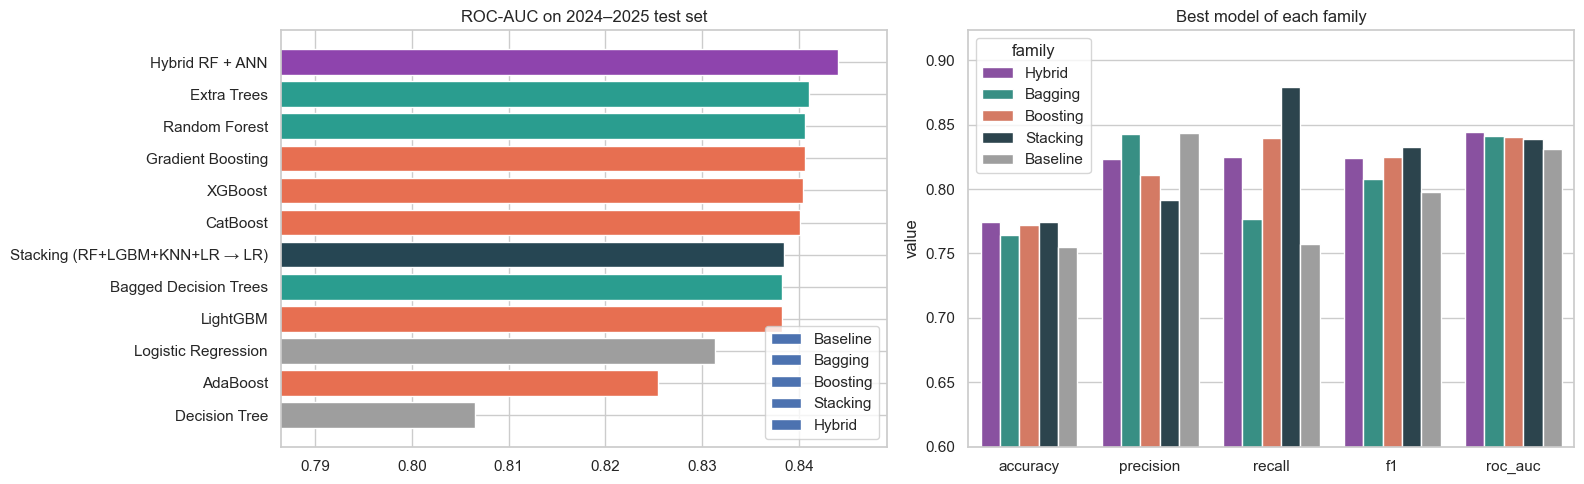

In [16]:
best_per_family = res.loc[res.groupby("family")["roc_auc"].idxmax()].sort_values("roc_auc", ascending=False)
display(best_per_family[["family", "model", "accuracy", "recall", "f1", "roc_auc"]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
pal = {"Baseline": "#9e9e9e", "Bagging": "#2a9d8f", "Boosting": "#e76f51", "Stacking": "#264653", "Hybrid": "#8e44ad"}
r2 = res.sort_values("roc_auc")
ax[0].barh(r2.model, r2.roc_auc, color=r2.family.map(pal))
ax[0].set_xlim(r2.roc_auc.min() - 0.02, r2.roc_auc.max() + 0.005); ax[0].set_title("ROC-AUC on 2024–2025 test set")
for fam, c in pal.items(): ax[0].barh([], [], color=c, label=fam)
ax[0].legend(loc="lower right")
melt = best_per_family.melt(id_vars="family", value_vars=["accuracy", "precision", "recall", "f1", "roc_auc"])
sns.barplot(data=melt, x="variable", y="value", hue="family", palette=pal, ax=ax[1])
ax[1].set_ylim(0.6, None); ax[1].set_title("Best model of each family"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### ROC curves & confusion matrices

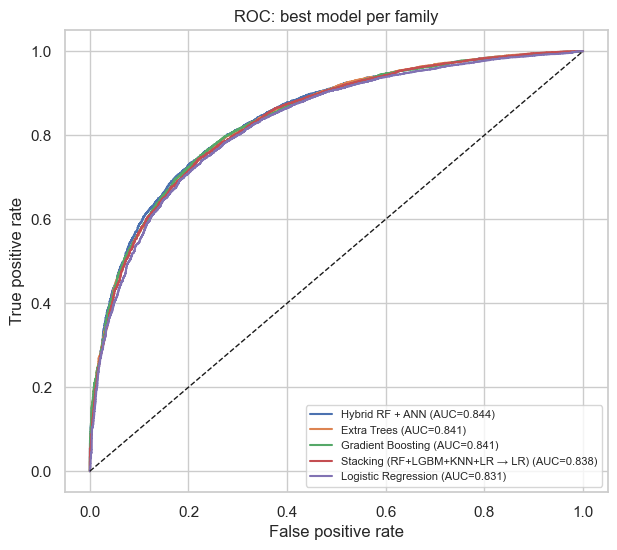

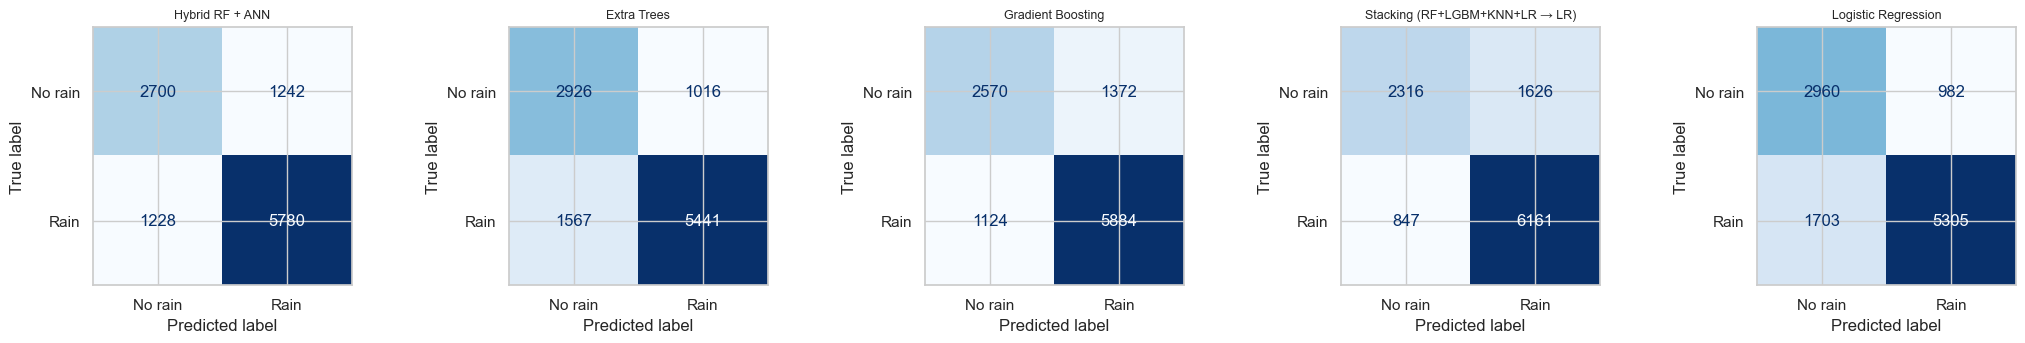

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in best_per_family.model:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set(xlabel="False positive rate", ylabel="True positive rate",
                                            title="ROC: best model per family"); ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(1, len(best_per_family), figsize=(4.2 * len(best_per_family), 3.6))
for a, name in zip(axes, best_per_family.model):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probas[name] >= .5).astype(int)),
                           display_labels=["No rain", "Rain"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

### Performance by climate zone (best overall model)

In [18]:
best_name = res.iloc[0].model
zone = (test.assign(p=probas[best_name], yhat=(probas[best_name] >= .5).astype(int))
            .groupby("climate_zone")
            .apply(lambda d: pd.Series({"accuracy": accuracy_score(d[TARGET], d.yhat),
                                        "recall": recall_score(d[TARGET], d.yhat),
                                        "f1": f1_score(d[TARGET], d.yhat),
                                        "roc_auc": roc_auc_score(d[TARGET], d.p)})))
print("Best model:", best_name); zone.round(4)

Best model: Hybrid RF + ANN


,accuracy,recall,f1,roc_auc
climate_zone,,,,
Dry,0.7356,0.7094,0.7413,0.8128
Intermediate,0.7712,0.8377,0.8273,0.8261
Wet,0.8208,0.9158,0.8858,0.8556


## 6. Interpretation: what drives the predictions?

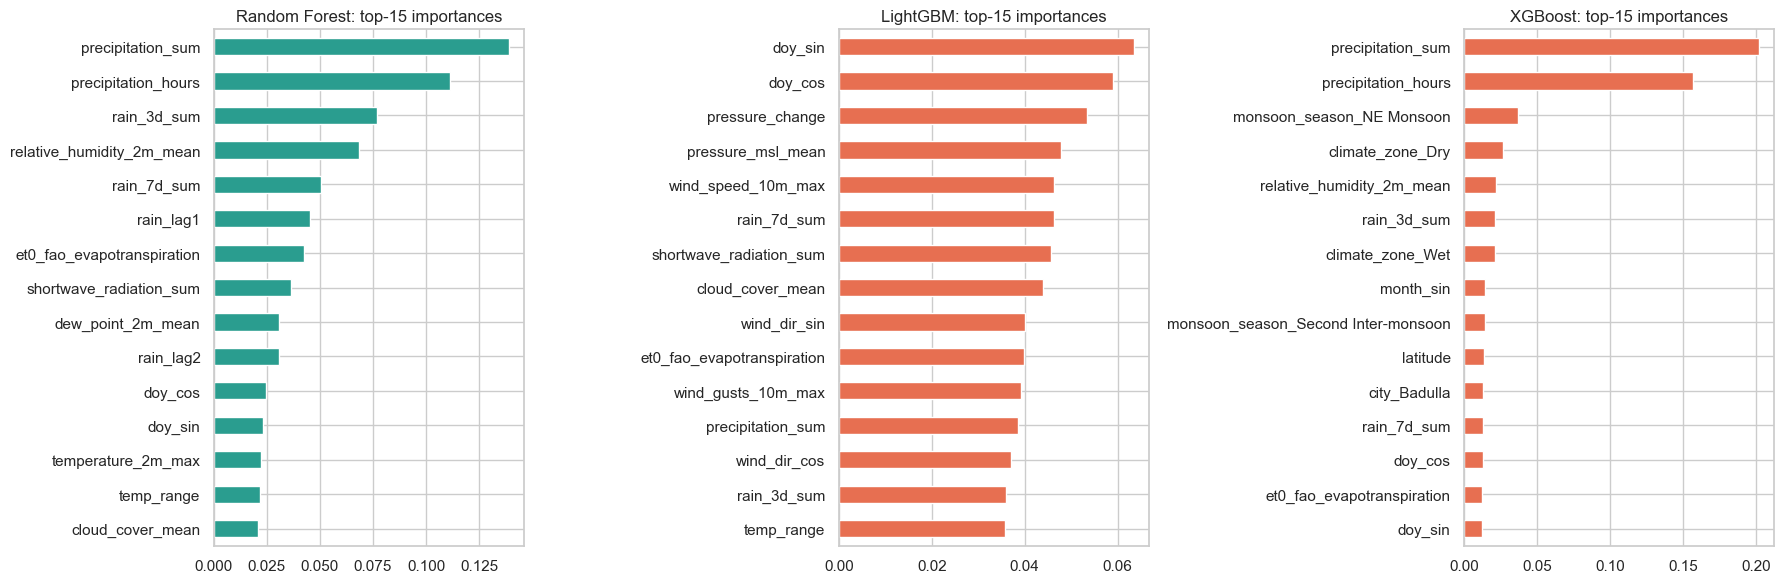

In [19]:
def tree_importance(name):
    pipe = fitted[name]
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pipe.named_steps["clf"].feature_importances_
    s = pd.Series(imp / imp.sum(), index=[n.split("__", 1)[1] for n in names])
    return s.sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, name, col in zip(ax, ["Random Forest", "LightGBM", "XGBoost"], ["#2a9d8f", "#e76f51", "#e76f51"]):
    tree_importance(name).head(15)[::-1].plot.barh(ax=a, color=col); a.set_title(f"{name}: top-15 importances")
plt.tight_layout(); plt.show()

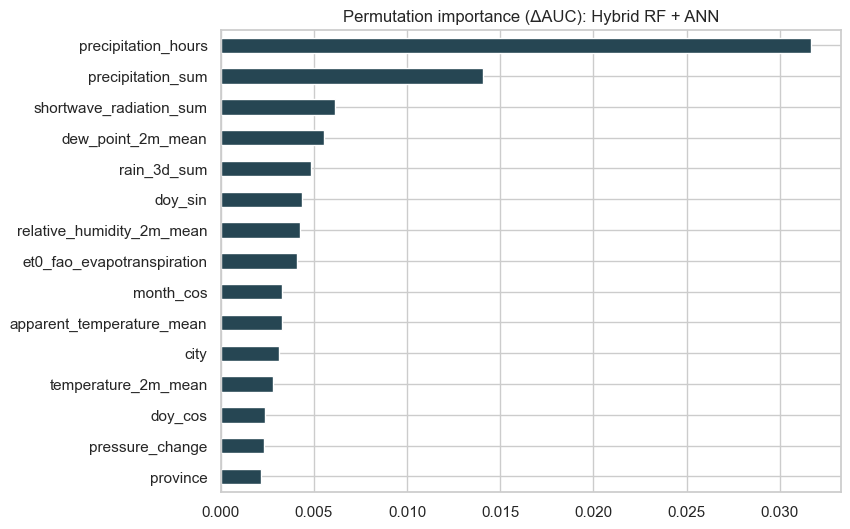

In [20]:
# Model-agnostic check: permutation importance of the best model on a test sample
sample = X_test.sample(3000, random_state=RANDOM_STATE)
pi = permutation_importance(fitted[best_name], sample, y_test.loc[sample.index], scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
perm.head(15)[::-1].plot.barh(figsize=(8, 6), color="#264653", title=f"Permutation importance (ΔAUC): {best_name}")
plt.show()

## 7. Save models & artefacts for the dashboard

In [21]:
registry = {}
for _, row in res.iterrows():
    fname = "models/" + row.model.lower().replace(" ", "_").replace("(", "").replace(")", "") \
                                  .replace("+", "").replace("→", "to").replace("__", "_") + ".joblib"
    joblib.dump(fitted[row.model], fname, compress=3)
    registry[row.model] = {"family": row.family, "file": fname}

importances = {n: tree_importance(n).head(20).round(5).to_dict()
               for n in ["Random Forest", "Extra Trees", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]}
importances["permutation_" + best_name] = perm.head(20).round(5).to_dict()

roc = {}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    idx = np.linspace(0, len(fpr) - 1, 150).astype(int)
    roc[name] = {"fpr": fpr[idx].round(4).tolist(), "tpr": tpr[idx].round(4).tolist()}

cms = {n: confusion_matrix(y_test, (p >= .5).astype(int)).tolist() for n, p in probas.items()}

meta = {"cat_features": CAT_FEATURES, "num_features": NUM_FEATURES, "features": FEATURES,
        "best_model": best_name, "registry": registry,
        "metrics": res.round(5).to_dict(orient="records"),
        "zone_metrics": zone.round(4).reset_index().to_dict(orient="records"),
        "importances": importances, "roc": roc, "confusion": cms,
        "rf_oob": round(float(rf.oob_score_), 5),
        "train_period": "2015-01-08 → 2023-12-31", "test_period": "2024-01-01 → 2025-12-30",
        "n_train": int(len(train)), "n_test": int(len(test))}
json.dump(meta, open("models/meta.json", "w"), indent=1)

# test-set rows (raw features + truth) so the dashboard can replay real days
test[["date"] + FEATURES + [TARGET]].to_csv("models/test_days.csv", index=False)
print("Saved", len(registry), "models →", sorted(os.listdir("models")))

Saved 12 models → ['adaboost.joblib', 'bagged_decision_trees.joblib', 'catboost.joblib', 'decision_tree.joblib', 'extra_trees.joblib', 'gradient_boosting.joblib', 'hybrid_rf_ann.joblib', 'lightgbm.joblib', 'logistic_regression.joblib', 'meta.json', 'random_forest.joblib', 'stacking_rflgbmknnlr_to_lr.joblib', 'test_days.csv', 'xgboost.joblib']


## 8. Discussion: why did this model win?

### Results summary (test set = 2024–2025, 10,950 city-days never seen in training; train = 49,215 city-days)

| Family | Best model | Accuracy | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Hybrid** | RF + ANN (soft voting) | 0.774 | 0.825 | 0.824 | **0.844** |
| **Bagging** | Extra Trees / Random Forest | 0.764 / 0.771 | 0.776 / 0.811 | 0.808 / 0.819 | 0.841 / 0.841 |
| **Boosting** | Gradient Boosting | 0.772 | 0.840 | 0.825 | 0.841 |
| **Stacking** | RF + LGBM + KNN + LR → LR | 0.774 | **0.879** | **0.833** | 0.839 |
| Baseline | Logistic Regression | 0.755 | 0.757 | 0.798 | 0.831 |
| Baseline | Single Decision Tree | 0.733 | 0.736 | 0.779 | 0.807 |

### Interpretation

**1. Every ensemble beats a single decision tree by a wide margin** (+3 to 4 points of AUC, +4 points of accuracy). A single deep tree has **high variance**: it memorises noisy day-to-day fluctuations. Bagging averages hundreds of de-correlated trees (bootstrap rows + random feature subsets), which cancels much of that variance. The Random Forest **OOB accuracy (≈0.795)** is close to its test accuracy, so it generalises well.

**2. Bagging, boosting and stacking end up very close (AUC 0.838 to 0.844).** This is an important, honest finding. Next-day rainfall in the tropics has a large **irreducible (noise) component**: convective afternoon showers are hard to predict from daily averages. Once the models have captured the strong signals (season × location, today's rain hours, pressure tendency, humidity, cloud cover), there is little systematic error left for boosting to remove. Boosting's main strength, reducing bias, therefore helps less here than on cleaner, more deterministic data. Among boosters, **Gradient Boosting** (shallow trees, `subsample=0.8`, i.e. stochastic boosting) did best. **AdaBoost** was weakest: re-weighting misclassified days makes it chase the noisy, inherently unpredictable rain days.

**3. Why the Hybrid RF + ANN scored the highest AUC.** The two members make *different kinds of errors*. The Random Forest splits on one feature at a time (axis-aligned, step-shaped boundaries) and is excellent at **location × season interactions** (e.g. Trincomalee in December vs July). The ANN learns **smooth, continuous combinations** of standardised features (humidity, dew point, pressure, radiation), which tree splits only approximate as staircases. Averaging their probabilities reduces variance further and gives the **best-ranked probabilities (AUC)**, which is what matters when the forecast is shown as a "% chance of rain".

**4. Why Stacking has the best F1 and recall.** The logistic meta-learner learned, from out-of-fold predictions, to trust the base models in a way that shifts predictions towards "rain". It catches **88% of actual rain days** at the cost of more false alarms (lower precision). For flood preparedness or agriculture, **missing a rain day is usually costlier than a false alarm**, so stacking is the best choice if recall is the priority. It is also the slowest model to train (5-fold × 4 base models).

**5. What drives the predictions?** Tree importances and model-agnostic permutation importance agree that the strongest signals are:
* **Season** (`doy_sin/cos`, month): the monsoon calendar.
* **Persistence**: today's `precipitation_hours`, `precipitation_sum` and the 3- and 7-day rain totals. Wet spells tend to continue.
* **Atmospheric state**: `pressure_change` (falling pressure precedes rain), humidity / dew point, cloud cover and solar radiation (sunny days mean dry air).

**6. Climate-zone effect.** Accuracy is highest in the **Wet zone (82%, recall 92%)** and lowest in the **Dry zone (74%)**. Dry-zone rain comes in fewer, more sporadic NE-monsoon and convective events, which are harder to anticipate. Class weighting kept dry-zone recall at a reasonable 71% instead of collapsing to "always dry".

### Conclusion
For Sri Lankan next-day rain prediction, **ensembles clearly beat single models**. The **Hybrid RF + ANN** gives the best overall discrimination (ROC-AUC 0.844) and **Stacking** gives the highest recall and F1. Because the bagging, boosting and stacking families score so close together, the choice should depend on the use case: Random Forest / Extra Trees for speed and simplicity (and a free OOB estimate), Stacking when catching every rain day matters, and the Hybrid for the best calibrated "% chance of rain".

**Limitations / future work:** daily ERA5 reanalysis rather than station observations; no upstream (neighbouring-city) or ocean (SST, MJO/ENSO index) features; the probability threshold could be tuned for a recall target.

## 9. Dashboard
An interactive **Streamlit** dashboard (`app.py`) loads the saved pipelines and lets a user:
* pick any city and either **replay a real day** from 2024–2025 or **enter custom weather values**,
* choose an ensemble model and get the **probability of rain tomorrow**, with every other model's prediction shown alongside for comparison,
* compare all models (metrics table, ROC curves, confusion matrices, Bagging vs Boosting vs Stacking chart),
* explore **feature importances** and the underlying Sri Lankan rainfall data.

Run it with:
```bash
pip install -r requirements.txt
streamlit run app.py
```

## 10. Generative AI disclosure
In line with the module's GenAI policy, I declare that **Claude (Anthropic), used through Claude Code**, assisted with this project: it helped write the data download script, the notebook code and the Streamlit dashboard, and drafted parts of the markdown explanations. I reviewed and ran all of the code myself, checked the results, and the interpretation and conclusions are my own.

## References
* Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api (data: ERA5, Copernicus Climate Change Service / ECMWF, CC BY 4.0)
* Breiman, L. (1996). *Bagging predictors* / (2001). *Random Forests*. Machine Learning.
* Freund & Schapire (1997), AdaBoost. Friedman (2001), Gradient Boosting.
* Chen & Guestrin (2016), XGBoost. Ke et al. (2017), LightGBM. Prokhorenkova et al. (2018), CatBoost.
* Wolpert, D. (1992). *Stacked generalization*. Neural Networks.
* Department of Meteorology, Sri Lanka: Climate of Sri Lanka (monsoon seasons): https://www.meteo.gov.lk